# 07 · Модель v2: кут панелей, тінь, сніг

У `06` знайшли: о 12–14 модель завищує, а панелі розвернуті з нахилом на захід. Тут:

1. **ясні дні** — що дає кут панелей (хмари не заважають);
2. **карта сонця** — напрямок × висота сонця → панелі дають більше чи менше, ніж горизонтальне скло;
3. **ефективність положення панелей** — формула: дата і час → скільки сонця ловить наша площина порівняно з горизонтальною;
4. фінальна модель v2 = v1 + ефективність положення + сніг та іній; кожна — без поправки, зі звичайною, динамічною і динамічною окремо для ранку і вечора.

**Дані вже очищені** (`02`): година обрізана, якщо батарея ≥ 93 % і мережа не потрібна хоча б пів години — тоді інвертор притискає сонце (раніше межа була 97 %, і провал о 13–16 на ясних днях був саме від цього); плюс 3 години збою.

Модель v1 — LightGBM (20 ознак) + динамічна поправка, 302 Вт (на очищених даних).

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
import data_io as io, evaluate as ev
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', None)
df, train, test = ev.load()
df = ev.extra_features(df)
clean = df[df.enough & ~df.clipped]; y = clean.pv_w; t = test.index
S = pd.Timestamp(ev.SPLIT, tz='UTC')
loc = clean.index.tz_convert(io.TZ)
days = ev.clear_days(df)
on_clear = loc.normalize().isin(days)
print(f'ясних днів без снігу: {len(days)} ({(days.year == 2025).sum()} у 2025, {(days.year == 2026).sum()} у 2026); чистих годин у них: {on_clear.sum():,}')

ясних днів без снігу: 247 (126 у 2025, 121 у 2026); чистих годин у них: 2,049


## 1. Ясні дні: що дає кут панелей

Скільки панелі дали на ясних днях відносно **горизонтального скла** за тієї ж радіації (ERA5): 1.0 — як горизонтальне, < 1 — менше (кут відвернутий або тінь), > 1 — більше (сонце в лице панелям).

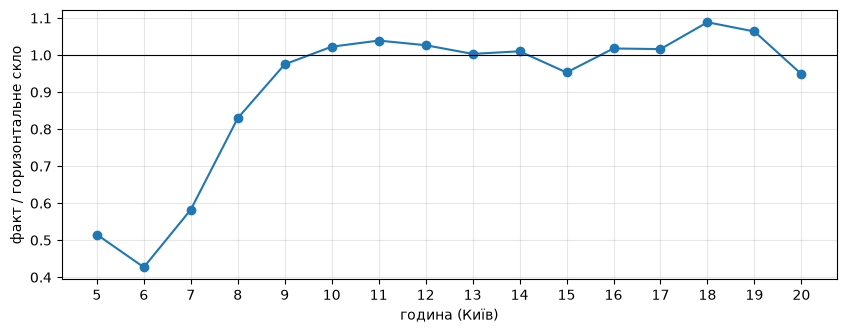

година (Київ),5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
годин,70.00,173.00,232.00,237.00,230.00,212.00,178.00,131.00,80.0,55.00,37.00,38.00,47.00,87.00,141.00,101.00
"факт, Вт",47.00,166.00,548.00,1453.00,2529.00,3304.00,3825.00,3951.00,3697.0,3270.00,2080.00,1677.00,1262.00,1067.00,614.00,178.00
факт / горизонт,0.52,0.43,0.58,0.83,0.97,1.02,1.04,1.03,1.0,1.01,0.95,1.02,1.02,1.09,1.06,0.95
"напрямок сонця, °",56.00,72.00,86.00,99.00,111.00,126.00,144.00,166.00,189.0,212.00,229.00,244.00,258.00,271.00,284.00,297.00
"висота сонця, °",2.00,7.00,13.00,22.00,32.00,39.00,46.00,49.00,49.0,44.00,31.00,24.00,18.00,15.00,10.00,4.00


In [2]:
c = clean[on_clear]
kg = ev.fit_scale(c.archive__shortwave_radiation, c.pv_w)
h = c.groupby(c.index.tz_convert(io.TZ).hour).apply(lambda x: pd.Series({
    'годин': len(x), 'факт, Вт': x.pv_w.mean(), 'факт / горизонт': x.pv_w.sum() / (kg * x.archive__shortwave_radiation).sum(),
    'напрямок сонця, °': x.sun_azimuth.mean(), 'висота сонця, °': x.sun_elevation.mean()}))
h.index.name = 'година (Київ)'
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(h.index, h['факт / горизонт'], 'o-'); ax.axhline(1, c='k', lw=.8)
ax.set_xlabel('година (Київ)'); ax.set_ylabel('факт / горизонтальне скло'); ax.set_xticks(h.index); plt.show()
h['годин'] = h['годин'].astype(int); h['факт, Вт'] = h['факт, Вт'].round().astype(int)
h[['напрямок сонця, °', 'висота сонця, °']] = h[['напрямок сонця, °', 'висота сонця, °']].round().astype(int)
h['факт / горизонт'] = h['факт / горизонт'].round(2); h.T

## 2. Карта сонця

Те саме, але по **положенню сонця**, а не годині: о 14:00 сонце взимку і влітку в різних місцях. Кожна клітинка — напрямок × висота сонця, колір — факт / горизонтальне скло на ясних днях. Синє — панелі дають менше (кут відвернутий або тінь), червоне — більше. Порожні клітинки — сонце там не буває або мало годин (< 5).

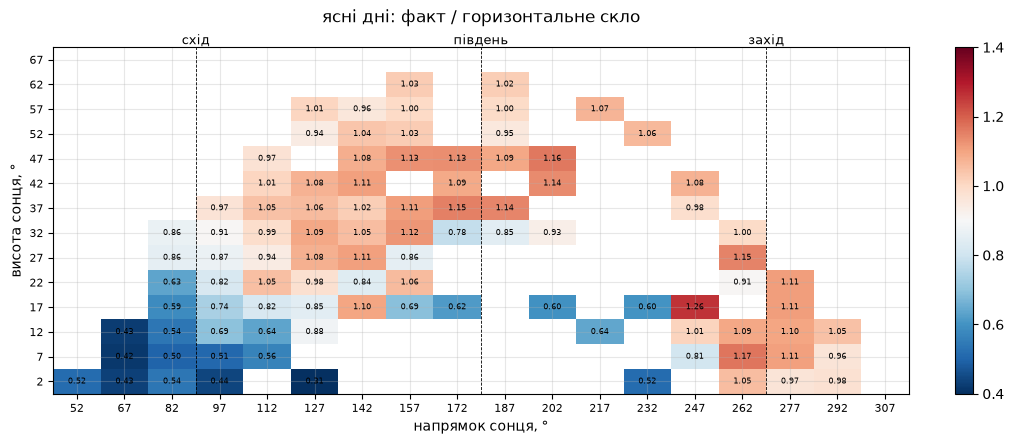

In [3]:
def show_map(m, cnt, title, vmin=.4, vmax=1.4):
    v = m.where(cnt >= 5)
    fig, ax = plt.subplots(figsize=(12, 4.5))
    im = ax.imshow(v.to_numpy(float), origin='lower', aspect='auto', cmap='RdBu_r', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(v.columns))); ax.set_xticklabels([int(i.mid) for i in v.columns], fontsize=8)
    ax.set_yticks(range(len(v.index))); ax.set_yticklabels([int(i.mid) for i in v.index], fontsize=8)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if pd.notna(v.iat[i, j]): ax.text(j, i, f'{v.iat[i, j]:.2f}', ha='center', va='center', fontsize=6)
    for x, name in ((90, 'схід'), (180, 'південь'), (270, 'захід')):
        ax.axvline((x - 45) / 15 - .5, c='k', lw=.6, ls='--'); ax.text((x - 45) / 15 - .5, len(v.index) - .5, name, ha='center', va='bottom', fontsize=9)
    ax.set_xlabel('напрямок сонця, °'); ax.set_ylabel('висота сонця, °'); ax.set_title(title, pad=18)
    plt.colorbar(im, ax=ax, fraction=.03); plt.show()

m_phys, cnt = ev.sun_map(c, c.pv_w, kg * c.archive__shortwave_radiation, prior=0)
show_map(m_phys, cnt, 'ясні дні: факт / горизонтальне скло')

Та сама карта, але відносно **моделі v1** (без поправки, прогноз на погоді ERA5 тут не потрібен — беремо її справжній прогноз): що модель **не врахувала**. Біле — модель влучає; синє — завищує; червоне — занижує.

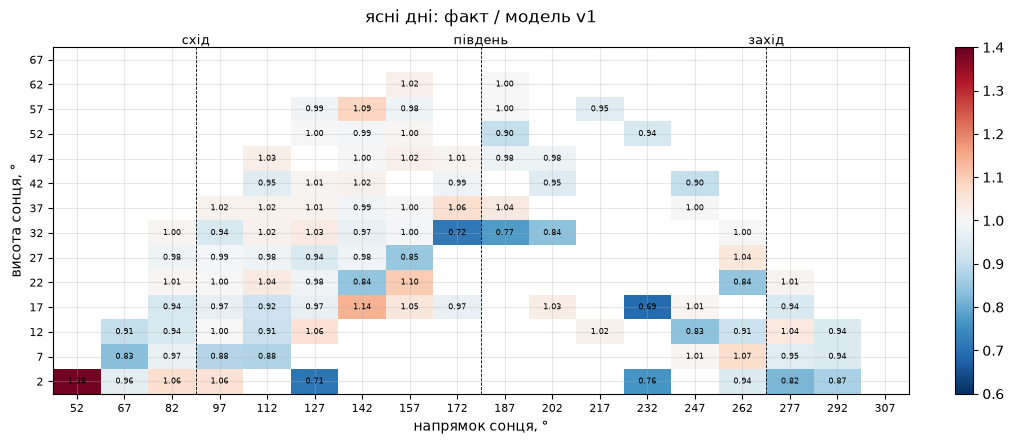

In [4]:
base = pd.read_pickle(io.DATA / 'corrections.pkl')['lgb']['без поправки'].reindex(clean.index)
m_v1, cnt1 = ev.sun_map(c, c.pv_w, base[on_clear], prior=0)
show_map(m_v1, cnt1, 'ясні дні: факт / модель v1', vmin=.6, vmax=1.4)

## 3. Орієнтація панелей з ясних днів

Підбір нахилу і напрямку площини, яка найкраще пояснює ясні дні (ERA5). Окремо по роках — орієнтація не мала змінитись.

In [5]:
def fit(rows):
    best = None
    for tilt in range(0, 65, 5):
        for az in range(90, 280, 10):
            x = ev.poa(rows, 'archive', tilt, az); k = ev.fit_scale(x, rows.pv_w)
            mae = np.nanmean(np.abs(k * x - rows.pv_w))
            if best is None or mae < best[0]: best = (mae, tilt, az, k)
    return best
cy = c.index.tz_convert(io.TZ).year
o = {name: fit(rows) for name, rows in (('ясні дні 2025', c[cy == 2025]), ('ясні дні 2026', c[cy == 2026]), ('усі ясні дні', c))}
flat = {name: np.nanmean(np.abs(ev.fit_scale(rows.archive__shortwave_radiation, rows.pv_w) * rows.archive__shortwave_radiation - rows.pv_w))
        for name, rows in (('ясні дні 2025', c[cy == 2025]), ('ясні дні 2026', c[cy == 2026]), ('усі ясні дні', c))}
pd.DataFrame({k: {'нахил, °': v[1], 'напрямок, °': v[2], 'промах площини, Вт': round(v[0]), 'промах горизонту, Вт': round(flat[k])} for k, v in o.items()}).T

,"нахил, °","напрямок, °","промах площини, Вт","промах горизонту, Вт"
ясні дні 2025,10,220,348,394
ясні дні 2026,15,190,280,329
усі ясні дні,10,210,319,368


## 4. Ефективність положення панелей (формула)

Для кожної дати й часу: скільки сонця при ясному небі потрапляє на нашу площину (нахил і напрямок — з ясних днів **2025-го**, щоб тест був чесним), з урахуванням втрат на відбиття від скла під гострим кутом, — поділене на ясне небо на горизонталі. Погода не потрібна, лише дата і час — тож так само рахується на Pi.

Складові (усе з pvlib): ясне небо Ineichen → перерахунок на площину (ізотропна модель неба) → втрати на відбиття (`pvlib.iam.physical`, формули Френеля для скла).

площина панелей: нахил 10°, напрямок 220° (180 — південь, 270 — захід)


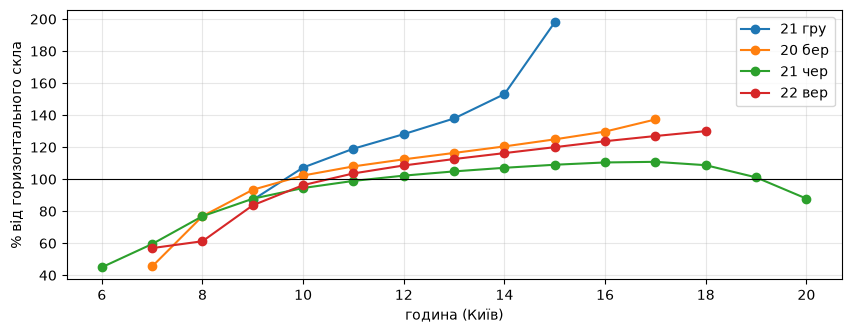

In [6]:
_, TILT, AZ, _ = o['ясні дні 2025']
print(f'площина панелей: нахил {TILT}°, напрямок {AZ}° (180 — південь, 270 — захід)')
fig, ax = plt.subplots(figsize=(10, 3.5))
for d, name in (('2025-12-21', '21 гру'), ('2025-03-20', '20 бер'), ('2025-06-21', '21 чер'), ('2025-09-22', '22 вер')):
    idx = pd.date_range(f'{d} 04:00', f'{d} 21:00', freq='1h', tz=io.TZ).tz_convert('UTC')
    f = ev.orient_factor(idx, TILT, AZ) * 100
    ax.plot(idx.tz_convert(io.TZ).hour, f, 'o-', label=name)
ax.axhline(100, c='k', lw=.8); ax.set_xlabel('година (Київ)'); ax.set_ylabel('% від горизонтального скла'); ax.legend(); plt.show()

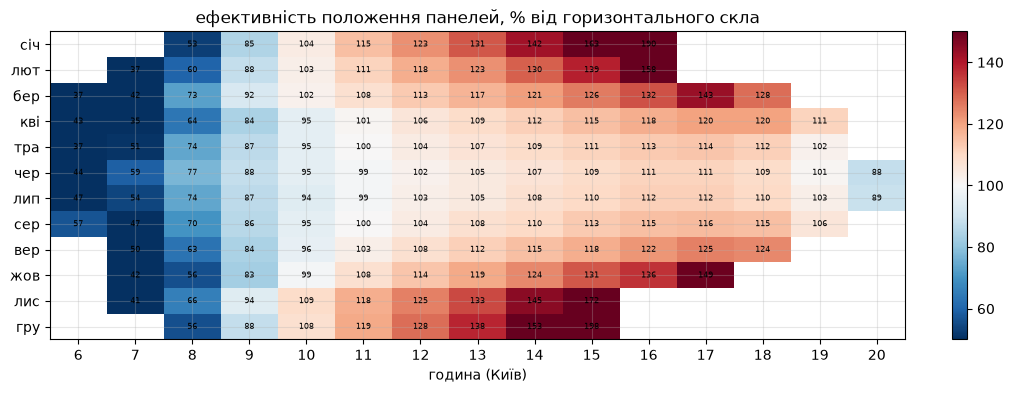

In [7]:
idx = pd.date_range('2025-01-01', '2025-12-31 23:00', freq='1h', tz='UTC')
of = ev.orient_factor(idx, TILT, AZ) * 100
li = idx.tz_convert(io.TZ)
hm = of.groupby([li.month, li.hour]).mean().unstack().round()
hm.index = MONTHS_UA = ['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру']
hm = hm.loc[:, hm.notna().any()]
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(hm.to_numpy(float), aspect='auto', cmap='RdBu_r', vmin=50, vmax=150)
ax.set_xticks(range(len(hm.columns))); ax.set_xticklabels(hm.columns); ax.set_yticks(range(12)); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        if pd.notna(hm.iat[i, j]): ax.text(j, i, int(hm.iat[i, j]), ha='center', va='center', fontsize=6)
ax.set_xlabel('година (Київ)'); ax.set_title('ефективність положення панелей, % від горизонтального скла'); plt.colorbar(im, ax=ax, fraction=.03); plt.show()

## 5. Модель v2 і поправки

- **v1** — 20 ознак;
- **+ ефективність положення** — формула вище як ознака;
- **+ сніг та іній** — 5 ознак з `06`;
- **v2** — і те, і те;
- **v2 × карта сонця** — поверх v2 ще й множник з карти «факт / модель» по положенню сонця (з ясних днів до початку кожного місяця, чесно).

Кожна — без поправки, зі звичайною (7 днів порівну), динамічною (свіжі дні важать більше) і динамічною **окремо для ранку і вечора** (ділимо за сонячним полуднем; ±1 год навколо полудня — спільна). Щомісяця перенавчання, перевірка 23 гру 2025 – 24 жов 2026.

In [8]:
day_rows = df.index[df.sun_elevation > 0]
df['orient_factor'] = np.nan
df.loc[day_rows, 'orient_factor'] = ev.orient_factor(day_rows, TILT, AZ).to_numpy()
clean = df[df.enough & ~df.clipped]; y = clean.pv_w
side = ev.solar_noon_side(clean.index)

PARAMS = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, random_state=0, verbose=-1)
fp = lambda X, yy, Xt: lgb.LGBMRegressor(**PARAMS).fit(X, yy).predict(Xt)
v1 = ev.variants()['повний (20 ознак)']
SNOW = ['snow_on_panels_cm', 'days_since_snow', 'forecast__snow_depth', 'night_min_temp', 'night_max_humidity']
MODELS = {'v1 (20 ознак)': v1, '+ ефективність положення': v1 + ['orient_factor'], '+ сніг та іній': v1 + SNOW,
          'v2: ефективність + сніг': v1 + ['orient_factor'] + SNOW}
raw = {k: ev.raw_all(df, fp, f) for k, f in MODELS.items()}
raw['v2 × карта сонця'] = ev.map_walk(df, raw['v2: ефективність + сніг'])

CORR = {'без поправки': lambda b: b,
        'звичайна 7 днів': lambda b: b * ev.recent_factor(b, y, 7),
        'динамічна': lambda b: b * ev.weighted_factor(b, y, 2),
        'динамічна, ранок і вечір окремо': lambda b: b * ev.weighted_side_factor(b, y, side, 2)}
preds = {(m, c): f(b).reindex(t) for m, b in raw.items() for c, f in CORR.items()}
table = pd.DataFrame({c: {m: ev.metrics(test.pv_w, preds[(m, c)])['MAE, Вт'] for m in raw} for c in CORR})
table.index.name = 'модель'; table.columns.name = 'середній промах, Вт →'
table

"середній промах, Вт →",без поправки,звичайна 7 днів,динамічна,"динамічна, ранок і вечір окремо"
модель,,,,
v1 (20 ознак),310,306,302,305
+ ефективність положення,306,304,299,302
+ сніг та іній,301,300,296,298
v2: ефективність + сніг,300,299,296,298
v2 × карта сонця,300,298,295,297


Найкращі комбінації проти v1 + динамічна (наша досі):

In [9]:
ref = preds[('v1 (20 ознак)', 'динамічна')]
win = t.tz_convert(io.TZ).month.isin([12, 1, 2, 3])
clr = t.tz_convert(io.TZ).normalize().isin(days)
rows = {}
for (m, c), v in preds.items():
    if c == 'без поправки': continue
    mt = ev.metrics(test.pv_w, v)
    rows[f'{m} + {c}'] = {'MAE, Вт': mt['MAE, Вт'], 'nMAE, %': mt['nMAE, %'], 'зсув, Вт': mt['зсув, Вт'],
                          'на ясних днях, Вт': ev.metrics(test.pv_w[clr], v[clr])['MAE, Вт'],
                          'взимку (гру–бер), Вт': ev.metrics(test.pv_w[win], v[win])['MAE, Вт'],
                          'краще за v1 + динамічна, % вибірок': '—' if (m, c) == ('v1 (20 ознак)', 'динамічна') else round(ev.daily_bootstrap(t, test.pv_w, v, ref) * 100)}
R = pd.DataFrame(rows).T.sort_values('MAE, Вт').head(10)
for col in ('MAE, Вт', 'зсув, Вт', 'на ясних днях, Вт', 'взимку (гру–бер), Вт'): R[col] = R[col].astype(int)
R.rename_axis('модель + поправка')

,"MAE, Вт","nMAE, %","зсув, Вт","на ясних днях, Вт","взимку (гру–бер), Вт","краще за v1 + динамічна, % вибірок"
модель + поправка,,,,,,
v2 × карта сонця + динамічна,295,24.4,8,254,234,99.0
+ сніг та іній + динамічна,296,24.5,8,258,235,98.0
v2: ефективність + сніг + динамічна,296,24.4,8,255,234,99.0
"v2 × карта сонця + динамічна, ранок і вечір окремо",297,24.6,3,258,235,89.0
"+ сніг та іній + динамічна, ранок і вечір окремо",298,24.7,3,261,238,80.0
"v2: ефективність + сніг + динамічна, ранок і вечір окремо",298,24.6,3,260,236,86.0
v2 × карта сонця + звичайна 7 днів,298,24.7,7,258,240,86.0
+ ефективність положення + динамічна,299,24.8,15,257,247,97.0
v2: ефективність + сніг + звичайна 7 днів,299,24.7,7,259,240,82.0


По годинах на ясних днях перевірки: факт / прогноз. Ідеал — рівна лінія на 1.

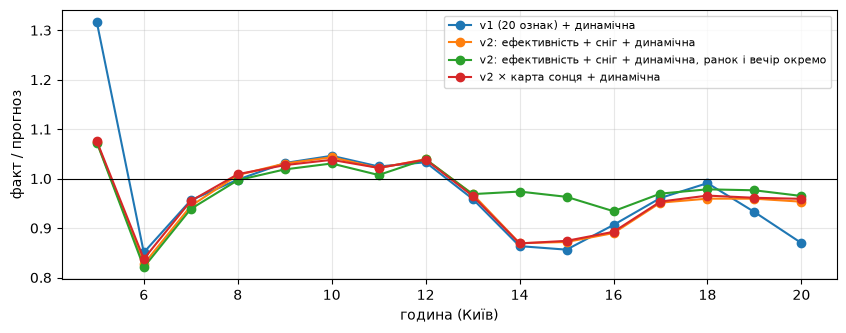

In [10]:
ct = test[clr]; hh = ct.index.tz_convert(io.TZ).hour
fig, ax = plt.subplots(figsize=(10, 3.5))
for key in [('v1 (20 ознак)', 'динамічна'), ('v2: ефективність + сніг', 'динамічна'), ('v2: ефективність + сніг', 'динамічна, ранок і вечір окремо'), ('v2 × карта сонця', 'динамічна')]:
    r = ct.pv_w.groupby(hh).sum() / preds[key][clr].groupby(hh).sum()
    ax.plot(r.index, r, 'o-', label=' + '.join(key))
ax.axhline(1, c='k', lw=.8); ax.set_xlabel('година (Київ)'); ax.set_ylabel('факт / прогноз'); ax.legend(fontsize=8); plt.show()

In [11]:
pd.to_pickle({'preds': preds, 'table': table, 'best': R, 'orient': (TILT, AZ), 'sun_map_phys': m_phys, 'sun_map_v1': m_v1}, io.DATA / 'model_v2.pkl')

## Висновки

1. **Після очищення даних провал о 13–16 на ясних днях зник** (0.95–1.02 від горизонту) — це була батарея, а не тінь. Лишилось: **ранок слабкий** (5–7 год: 0.43–0.58 — панелі відвернуті від сходу), **вечір сильний** (18–19 год: 1.06–1.09 — сонце в лице панелям). Площина з ясних днів 2025: нахил 10°, напрямок 220° (південний захід).
2. **Карта сонця:** синя зона — низьке сонце зі сходу (кут і, можливо, перешкода) і низьке зимове сонце з півдня (висота ~17°: 0.6) — схоже на перешкоду з півдня, яку видно лише взимку. Червона — вечірнє сонце з заходу.
3. **Модель v2 краща за v1:** v2 (ефективність положення + сніг та іній) + динамічна поправка — **296 Вт** (24 % від середньої генерації) проти 302 у v1, краще у **99 %** вибірок. Окремо: ефективність положення 302 → 299, сніг та іній 302 → 296; разом — 296.
4. **Карта сонця поверх v2 майже нічого не додає** (296 → 295): ефективність положення вже дає моделі те саме.
5. **Динамічна поправка окремо для ранку і вечора — гірша** за спільну (298 проти 296), хоча на ясних днях вирівнює криву після обіду. Звичайна 7 днів — 299, без поправки — 300.
6. **Фінальна модель: v2 + динамічна поправка, 296 Вт** (точність за день ~85 %). Формула ефективності положення рахується з дати й часу — так само на Pi.